<a href="https://colab.research.google.com/github/AaronGoldblatt/persistent-pepper/blob/main/notebooks/pepper_colab_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pepper — Colab Training Notebook

End-to-end training on Google Colab. This notebook is the primary runner
for the GPU-bound parts of the project; the Mac side of the workflow is
scoped to code editing, raw image curation, and final report assembly.

Flow:
  0. Sanity-check the allocated GPU.
  1. Mount Google Drive.
  2. Configure Drive-backed cache paths.
  3. Clone the repo and install dependencies.
  4. One-time: download Stable Diffusion 1.5 into the Drive cache.
  5. Sync raw Pepper photos from Drive into the working tree.
  6. Preprocess + caption the dataset.
  7. Train Textual Inversion (checkpoints stream to Drive).
  8. Train DreamBooth (checkpoints stream to Drive).
  9. Evaluate one or both checkpoints with the manual DDIM sampler + CLIP.

Recommended Colab runtimes: T4 (free) is sufficient for both methods; L4
or A100 (Pro) roughly 3x faster for DreamBooth.

## 0. GPU sanity check

In [1]:
!nvidia-smi

import torch
assert torch.cuda.is_available(), (
    'No CUDA device detected. In Colab: Runtime > Change runtime type > GPU.'
)
print('CUDA device:', torch.cuda.get_device_name(0))
print('Total VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

Wed May 13 02:39:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 1. Mount Google Drive

Everything that needs to survive runtime disconnects lives under Drive:
raw photos, the SD 1.5 weight cache, and training checkpoints.

In [2]:
from google.colab import drive

DRIVE_MOUNT_ROOT = '/content/gdrive'
drive.mount(DRIVE_MOUNT_ROOT)

Mounted at /content/gdrive


## 2. Drive-backed cache layout

Edit `DRIVE_CACHE_ROOT` and `DRIVE_RAW_IMAGES_DIRECTORY` to match where you
keep Pepper's photos and where you want weights cached. Everything else is
derived from these two paths.

In [3]:
import os
from pathlib import Path

MY_DRIVE_ROOT = Path(DRIVE_MOUNT_ROOT) / 'MyDrive'
DRIVE_PROJECT_ROOT = MY_DRIVE_ROOT / 'persistent-pepper'
DRIVE_CREDENTIALS_DIRECTORY = MY_DRIVE_ROOT / 'cs5788'
DRIVE_CACHE_ROOT = DRIVE_PROJECT_ROOT / 'cache'
DRIVE_RAW_IMAGES_DIRECTORY = DRIVE_PROJECT_ROOT / 'data' / 'raw'

GITHUB_TOKEN_FILE_PATH = DRIVE_CREDENTIALS_DIRECTORY / 'token.txt'
GITHUB_USERNAME_FILE_PATH = DRIVE_CREDENTIALS_DIRECTORY / 'git_username.txt'

DRIVE_SD_MODEL_DIRECTORY = DRIVE_CACHE_ROOT / 'sd-v1-5'
DRIVE_CHECKPOINTS_ROOT = DRIVE_CACHE_ROOT / 'checkpoints'
DRIVE_CLASS_PRIOR_DIRECTORY = DRIVE_CACHE_ROOT / 'class_prior_dog'
DRIVE_PROCESSED_IMAGES_DIRECTORY = DRIVE_CACHE_ROOT / 'processed'
DRIVE_CAPTIONS_FILE_PATH = DRIVE_CACHE_ROOT / 'captions.json'

TEXTUAL_INVERSION_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'textual_inversion'
DREAMBOOTH_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'dreambooth'

for directory_to_ensure in [
    DRIVE_PROJECT_ROOT,
    DRIVE_CACHE_ROOT,
    DRIVE_SD_MODEL_DIRECTORY,
    DRIVE_CHECKPOINTS_ROOT,
    DRIVE_CLASS_PRIOR_DIRECTORY,
    DRIVE_PROCESSED_IMAGES_DIRECTORY,
    DRIVE_RAW_IMAGES_DIRECTORY,
    TEXTUAL_INVERSION_OUTPUT_DIRECTORY,
    DREAMBOOTH_OUTPUT_DIRECTORY,
]:
    directory_to_ensure.mkdir(parents=True, exist_ok=True)

os.environ['PEPPER_SD_MODEL'] = str(DRIVE_SD_MODEL_DIRECTORY)
print('Drive project root: ', DRIVE_PROJECT_ROOT)
print('SD 1.5 cache:      ', DRIVE_SD_MODEL_DIRECTORY)
print('Checkpoints root:  ', DRIVE_CHECKPOINTS_ROOT)
print('Raw images source: ', DRIVE_RAW_IMAGES_DIRECTORY)
print('Token file path:   ', GITHUB_TOKEN_FILE_PATH)

Drive project root:  /content/gdrive/MyDrive/persistent-pepper
SD 1.5 cache:       /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Checkpoints root:   /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints
Raw images source:  /content/gdrive/MyDrive/persistent-pepper/data/raw
Token file path:    /content/gdrive/MyDrive/cs5788/token.txt


## 3. Clone the private repository and install dependencies

This cell reads your GitHub token from `MyDrive/cs5788/token.txt` and your
GitHub username from `MyDrive/cs5788/git_username.txt`, then clones the private
`AaronGoldblatt/persistent-pepper` repo into Colab's local SSD at
`/content/persistent-pepper`.

The token is never printed. Keep both credential files out of the repo.

In [15]:
import subprocess

GITHUB_REPOSITORY_OWNER = 'AaronGoldblatt'
GITHUB_REPOSITORY_NAME = 'persistent-pepper'
BRANCH_NAME = 'main'
LOCAL_REPOSITORY_ROOT = Path('/content/persistent-pepper')

if not GITHUB_TOKEN_FILE_PATH.is_file():
    raise FileNotFoundError(
        f'Missing GitHub token file: {GITHUB_TOKEN_FILE_PATH}. '
        'Create it in Drive with only the token on the first line.'
    )
if not GITHUB_USERNAME_FILE_PATH.is_file():
    raise FileNotFoundError(
        f'Missing GitHub username file: {GITHUB_USERNAME_FILE_PATH}. '
        'Create it in Drive with only your GitHub username on the first line.'
    )

github_token = GITHUB_TOKEN_FILE_PATH.read_text().strip().splitlines()[0]
github_username = GITHUB_USERNAME_FILE_PATH.read_text().strip().splitlines()[0]
authenticated_repository_url = (
    f'https://{github_token}@github.com/'
    f'{GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME}.git'
)
public_repository_url = (
    f'https://github.com/{GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME}.git'
)


def run_git_command(command_parts, working_directory=None):
    completed_process = subprocess.run(
        command_parts,
        cwd=working_directory,
        capture_output=True,
        text=True,
    )
    if completed_process.returncode != 0:
        sanitized_command_parts = [
            command_part.replace(github_token, '[GITHUB_TOKEN]')
            for command_part in command_parts
        ]
        sanitized_stderr = completed_process.stderr.replace(github_token, '[GITHUB_TOKEN]')
        sanitized_stdout = completed_process.stdout.replace(github_token, '[GITHUB_TOKEN]')
        raise RuntimeError(
            'Git command failed:\n'
            f'command: {sanitized_command_parts}\n'
            f'stdout: {sanitized_stdout}\n'
            f'stderr: {sanitized_stderr}'
        )
    return completed_process


if not LOCAL_REPOSITORY_ROOT.exists():
    run_git_command(
        [
            'git',
            'clone',
            '--branch',
            BRANCH_NAME,
            '--single-branch',
            authenticated_repository_url,
            str(LOCAL_REPOSITORY_ROOT),
        ]
    )
else:
    run_git_command(
        ['git', 'remote', 'set-url', 'origin', authenticated_repository_url],
        working_directory=LOCAL_REPOSITORY_ROOT,
    )
    run_git_command(
        ['git', 'checkout', BRANCH_NAME],
        working_directory=LOCAL_REPOSITORY_ROOT,
    )
    run_git_command(
        ['git', 'pull', '--ff-only'],
        working_directory=LOCAL_REPOSITORY_ROOT,
    )

run_git_command(
    ['git', 'remote', 'set-url', 'origin', public_repository_url],
    working_directory=LOCAL_REPOSITORY_ROOT,
)

%cd {LOCAL_REPOSITORY_ROOT}
!python -m pip -q install -r requirements.txt

print(f'Using private repo {GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME} as {github_username}.')
print('Repository root:', LOCAL_REPOSITORY_ROOT)

/content/persistent-pepper
Using private repo AaronGoldblatt/persistent-pepper as AaronGoldblatt.
Repository root: /content/persistent-pepper


## 4. One-time: download Stable Diffusion 1.5 into the Drive cache

Runs once per Drive account. If `DRIVE_SD_MODEL_DIRECTORY` already has the
weights, this no-ops within seconds. The first run downloads ~4 GB.

In [ ]:
!rm -rf /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5

In [ ]:
!/usr/bin/python3 -m pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 660.6/660.6 kB 13.2 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.11.0
    Uninstalling huggingface_hub-1.11.0:
      Successfully uninstalled huggingface_hub-1.11.0


In [ ]:
weights_already_cached = (DRIVE_SD_MODEL_DIRECTORY / 'unet' / 'diffusion_pytorch_model.safetensors').is_file() \
    or (DRIVE_SD_MODEL_DIRECTORY / 'unet' / 'diffusion_pytorch_model.bin').is_file()

if not weights_already_cached:
    !hf download stable-diffusion-v1-5/stable-diffusion-v1-5 \
    --local-dir {DRIVE_SD_MODEL_DIRECTORY} \
    --include "tokenizer/*" \
    --include "text_encoder/config.json" \
    --include "text_encoder/model.safetensors" \
    --include "vae/config.json" \
    --include "vae/diffusion_pytorch_model.safetensors" \
    --include "unet/config.json" \
    --include "unet/diffusion_pytorch_model.safetensors" \
    --include "scheduler/scheduler_config.json"
else:
    print('SD 1.5 weights already cached at', DRIVE_SD_MODEL_DIRECTORY)

Fetching 11 files:   0% 0/11 [00:00<?, ?it/s]Still waiting to acquire lock on /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)
Still waiting to acquire lock on /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)
Still waiting to acquire lock on /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)
Still waiting to acquire lock on /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)
Fetching 11 files: 100% 11/11 [00:17<00:00,  1.55s/it]
Download complete: : 4.27GB [00:17, 402MB/s]              ✓ Downloaded
  path: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Download complete: : 4.27GB [00:17, 250MB/s]


## 5. Sync raw Pepper photos from Drive to the local working tree

We copy rather than symlink so the preprocess step reads from local SSD,
which is 5-10x faster than reading from Drive on each call.

In [ ]:
LOCAL_RAW_IMAGES_DIRECTORY = LOCAL_REPOSITORY_ROOT / 'data' / 'raw'
LOCAL_RAW_IMAGES_DIRECTORY.mkdir(parents=True, exist_ok=True)

!rsync -a --delete \
    --exclude '.gitkeep' \
    {DRIVE_RAW_IMAGES_DIRECTORY}/ {LOCAL_RAW_IMAGES_DIRECTORY}/

raw_file_count = sum(
    1 for _ in LOCAL_RAW_IMAGES_DIRECTORY.iterdir() if _.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'}
)
print(f'{raw_file_count} raw images present in {LOCAL_RAW_IMAGES_DIRECTORY}')
assert raw_file_count > 0, (
    f'No raw images found. Upload your Pepper photos to {DRIVE_RAW_IMAGES_DIRECTORY} first.'
)

24 raw images present in /content/persistent-pepper/data/raw


## 6. Preprocess and caption

Processed images and the captions JSON are written directly to the Drive
cache so subsequent runs skip the BLIP caption pass (which is the slowest
part of dataset prep).

In [ ]:
!python scripts/preprocess_images.py \
    --raw_images_directory {LOCAL_RAW_IMAGES_DIRECTORY} \
    --processed_images_directory {DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --target_resolution 512

Preprocessed 24 images into /content/gdrive/MyDrive/persistent-pepper/cache/processed at 512x512.


In [ ]:
if not DRIVE_CAPTIONS_FILE_PATH.is_file() or DRIVE_CAPTIONS_FILE_PATH.stat().st_size < 10:
    !python scripts/generate_captions.py \
        --processed_images_directory {DRIVE_PROCESSED_IMAGES_DIRECTORY} \
        --captions_output_path {DRIVE_CAPTIONS_FILE_PATH}
else:
    print('Captions already cached at', DRIVE_CAPTIONS_FILE_PATH)

preprocessor_config.json: 100% 445/445 [00:00<00:00, 3.03MB/s]
The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
config.json: 4.60kB [00:00, 15.5MB/s]
tokenizer_config.json: 100% 527/527 [00:00<00:00, 4.07MB/s]
vocab.txt: 232kB [00:00, 10.4MB/s]
tokenizer.json: 711kB [00:00, 56.4MB/s]
special_tokens_map.json: 100% 125/125 [00:00<00:00, 1.02MB/s]
model.safetensors: 100% 1.88G/1.88G [00:08<00:00, 234MB/s]
Loading weights: 100% 616/616 [00:00<00:00, 712.11it/s, Materializing param=vision_model.post_layernorm.weight]
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will

## 7. Train Textual Inversion

Overrides redirect every input/output path at the Drive cache so the run
is crash-safe. Checkpoint cadence is controlled by
`checkpoint_every_n_steps` in the config.

In [ ]:

# ── Training preview gallery ──────────────────────────────────────────────────
# The training loop saves a preview image every `preview_every_n_steps` steps
# into  <output_directory>/previews/.  Run this cell after (or during) training
# to display the progression inline.

import math
import matplotlib.pyplot as plt
from PIL import Image

def show_training_previews(output_directory, max_columns=5, figure_title=None):
    previews_dir = output_directory / 'previews'
    preview_paths = sorted(previews_dir.glob('preview_step_*.png')) if previews_dir.is_dir() else []

    if not preview_paths:
        print(f'No preview images found in {previews_dir}.')
        print('Previews are saved during training — re-run this cell after training starts.')
        return

    n = len(preview_paths)
    n_cols = min(n, max_columns)
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.8 * n_rows), squeeze=False)

    for idx, path in enumerate(preview_paths):
        row, col = divmod(idx, n_cols)
        ax = axes[row][col]
        ax.imshow(Image.open(path).convert('RGB'))
        ax.axis('off')
        step_label = path.stem.replace('preview_step_', 'step ')
        ax.set_title(step_label, fontsize=9)

    for idx in range(n, n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        axes[row][col].axis('off')

    if figure_title:
        fig.suptitle(figure_title, fontsize=13, weight='bold', y=1.01)
    fig.tight_layout()
    plt.show()
    print(f'Displayed {n} preview image(s) from {previews_dir}')


show_training_previews(
    TEXTUAL_INVERSION_OUTPUT_DIRECTORY,
    figure_title='Textual Inversion — training preview progression',
)


In [ ]:
TEXTUAL_INVERSION_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'textual_inversion'

!python scripts/train.py \
    --method textual_inversion \
    --config configs/textual_inv_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override output_directory={TEXTUAL_INVERSION_OUTPUT_DIRECTORY}

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading weights: 100% 196/196 [00:00<00:00, 1140.68it/s, Materializing param=text_model.final_layer_norm.weight]
CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disa

## 8. Train DreamBooth

First run on a fresh Drive will auto-generate ~100 class-prior dog images
into `DRIVE_CLASS_PRIOR_DIRECTORY`; subsequent runs reuse them. Full
UNet checkpoints are ~3.4 GB each, so set `checkpoint_every_n_steps` in
the YAML to a value you're comfortable writing to Drive.

In [ ]:
DREAMBOOTH_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'dreambooth'

!python scripts/train.py \
    --method dreambooth \
    --config configs/dreambooth_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override class_prior_images_directory={DRIVE_CLASS_PRIOR_DIRECTORY} \
    --override output_directory={DREAMBOOTH_OUTPUT_DIRECTORY}

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading weights: 100% 196/196 [00:10<00:00, 18.52it/s, Materializing param=text_model.final_layer_norm.weight]
CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
dreambooth:  21% 250/1200 [04:36<10:33,  1.50it/s, prior=0.0078, subject=0.0105]
Writing model shards:   0% 0/1 [00:00<?, ?it/s]
Writing model shards: 100% 1/1 [01:23<00:00, 83.28s/it]
dreambooth:  42% 500/1200 [10:38<07

## 9. Generate presentation-ready samples

This section generates the same prompt set for both methods and writes each
method's outputs to a separate evaluation folder. The next section turns those
folders into a labeled comparison grid that is easy to screenshot or save for
the final report.

In [ ]:
import subprocess

PRESENTATION_PROMPTS = [
    'a photo of {subject} sitting on a couch',
    'a close-up portrait of {subject}',
    'a photo of {subject} wearing sunglasses',
    'an oil painting of {subject} in the style of Van Gogh',
]

EVALUATION_RUNS = {
    'textual_inversion': {
        'checkpoint_path': TEXTUAL_INVERSION_OUTPUT_DIRECTORY / 'learned_embedding_final.bin',
        'subject_identifier_phrase': '<pepper>',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_textual_inversion_presentation',
    },
    'dreambooth': {
        'checkpoint_path': DREAMBOOTH_OUTPUT_DIRECTORY / 'latest',
        'subject_identifier_phrase': 'sks dog',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_dreambooth_presentation',
    },
}

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    evaluate_command = [
        'python',
        'scripts/evaluate.py',
        '--method',
        method_name,
        '--pretrained_model_name_or_path',
        str(DRIVE_SD_MODEL_DIRECTORY),
        '--checkpoint_path',
        str(evaluation_settings['checkpoint_path']),
        '--reference_images_directory',
        str(DRIVE_PROCESSED_IMAGES_DIRECTORY),
        '--subject_identifier_phrase',
        evaluation_settings['subject_identifier_phrase'],
        '--output_directory',
        str(evaluation_settings['output_directory']),
    ]
    for prompt_text in PRESENTATION_PROMPTS:
        evaluate_command.extend(['--prompt', prompt_text])

    print(f'Running presentation evaluation for {method_name}...')
    subprocess.run(evaluate_command, check=True)

Running presentation evaluation for textual_inversion...
Running presentation evaluation for dreambooth...


In [17]:
# CLIP reports on existing images

import importlib
import src.utils.metrics
importlib.reload(src.utils.metrics)
# Re-import after reload
from src.utils.metrics import compute_clip_similarity_report

from src.utils.metrics import (
    compute_clip_similarity_report,
    format_report_as_human_readable_text,
    load_pil_images_from_directory,
)
from PIL import Image

PRESENTATION_PROMPTS = [
    'a photo of {subject} sitting on a couch',
    'a close-up portrait of {subject}',
    'a photo of {subject} wearing sunglasses',
    'an oil painting of {subject} in the style of Van Gogh',
]

EVALUATION_RUNS = {
    'textual_inversion': {
        'checkpoint_path': TEXTUAL_INVERSION_OUTPUT_DIRECTORY / 'learned_embedding_final.bin',
        'subject_identifier_phrase': '<pepper>',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_textual_inversion_presentation',
    },
    'dreambooth': {
        'checkpoint_path': DREAMBOOTH_OUTPUT_DIRECTORY / 'latest',
        'subject_identifier_phrase': 'sks dog',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_dreambooth_presentation',
    },
}

reference_pil_images = load_pil_images_from_directory(DRIVE_PROCESSED_IMAGES_DIRECTORY)

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    output_dir = evaluation_settings['output_directory']
    subject = evaluation_settings['subject_identifier_phrase']

    generated_pil_images = [
        Image.open(p).convert('RGB')
        for p in sorted(output_dir.glob('gen_*.png'))
    ]
    fully_substituted_prompts = [
        p.format(subject=subject) for p in PRESENTATION_PROMPTS
    ]

    report = compute_clip_similarity_report(
        generated_pil_images=generated_pil_images,
        reference_pil_images=reference_pil_images,
        prompts_used_for_generation=fully_substituted_prompts,
    )
    report_text = format_report_as_human_readable_text(report)
    print(f'\n{"="*80}\n{method_name}')
    print(report_text)
    (output_dir / 'clip_report.txt').write_text(report_text)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



textual_inversion
CLIP-I (identity, gen vs refs):   0.7410
CLIP-T (prompt alignment):        0.2730
# generated images considered:    4
# reference images considered:    24


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



dreambooth
CLIP-I (identity, gen vs refs):   0.8107
CLIP-T (prompt alignment):        0.2357
# generated images considered:    4
# reference images considered:    24


## 10. Labeled comparison figures

This renders a compact report figure: columns are standardized prompts and rows
are the two personalization methods. It also saves the figure into the Drive
checkpoint folder so it can be used directly in the project writeup.

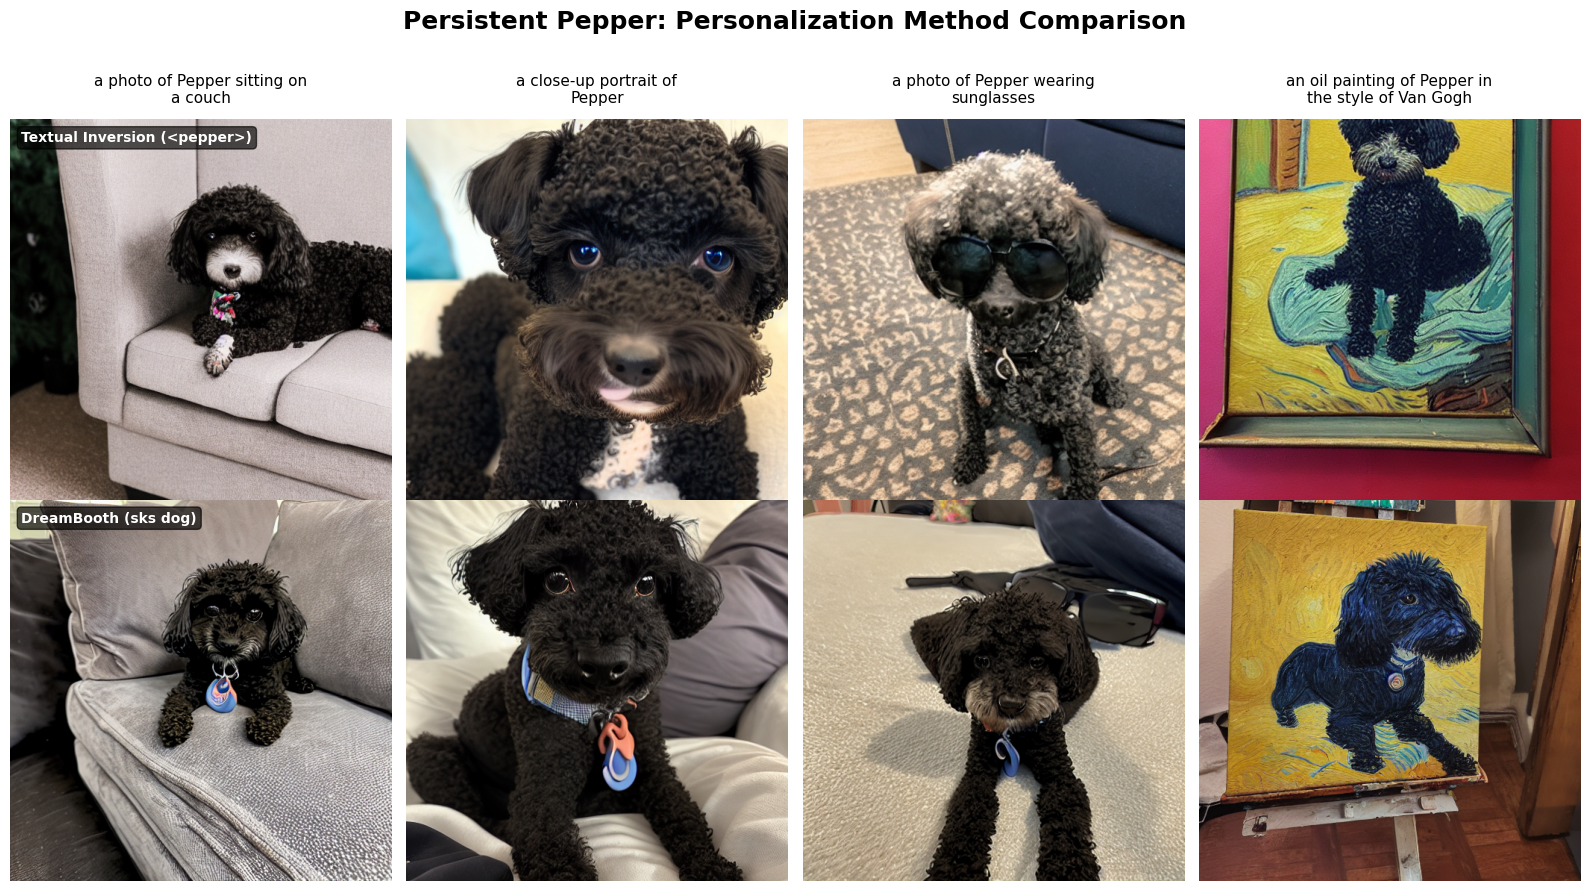

Saved presentation figure to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/persistent_pepper_method_comparison.png

Textual Inversion (<pepper>)
CLIP-I (identity, gen vs refs):   0.7410
CLIP-T (prompt alignment):        0.2730
# generated images considered:    4
# reference images considered:    24

DreamBooth (sks dog)
CLIP-I (identity, gen vs refs):   0.8107
CLIP-T (prompt alignment):        0.2357
# generated images considered:    4
# reference images considered:    24


In [18]:
import textwrap

import matplotlib.pyplot as plt
from PIL import Image

METHOD_DISPLAY_NAMES = {
    'textual_inversion': 'Textual Inversion (<pepper>)',
    'dreambooth': 'DreamBooth (sks dog)',
}

number_of_methods = len(EVALUATION_RUNS)
number_of_prompts = len(PRESENTATION_PROMPTS)
figure, axes_grid = plt.subplots(
    number_of_methods,
    number_of_prompts,
    figsize=(4.0 * number_of_prompts, 4.4 * number_of_methods),
    squeeze=False,
)

for row_index, (method_name, evaluation_settings) in enumerate(EVALUATION_RUNS.items()):
    generated_image_paths = sorted(evaluation_settings['output_directory'].glob('gen_*.png'))
    if len(generated_image_paths) < number_of_prompts:
        raise FileNotFoundError(
            f"Expected at least {number_of_prompts} generated images for {method_name}, "
            f"but found {len(generated_image_paths)} in {evaluation_settings['output_directory']}. "
            'Rerun Step 9 after retraining with the latest code.'
        )

    for column_index, generated_image_path in enumerate(generated_image_paths[:number_of_prompts]):
        axis = axes_grid[row_index][column_index]
        axis.imshow(Image.open(generated_image_path).convert('RGB'))
        axis.axis('off')

        if row_index == 0:
            prompt_title = PRESENTATION_PROMPTS[column_index].replace('{subject}', 'Pepper')
            axis.set_title(
                textwrap.fill(prompt_title, width=28),
                fontsize=11,
                pad=12,
            )

        if column_index == 0:
            axis.text(
                0.03, 0.97,
                METHOD_DISPLAY_NAMES[method_name],
                transform=axis.transAxes,
                fontsize=10,
                weight='bold',
                va='top',
                ha='left',
                color='white',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.65),
            )

figure.suptitle(
    'Persistent Pepper: Personalization Method Comparison',
    fontsize=18,
    weight='bold',
    y=1.02,
)
figure.tight_layout()

presentation_figure_path = DRIVE_CHECKPOINTS_ROOT / 'persistent_pepper_method_comparison.png'
figure.savefig(
    presentation_figure_path,
    dpi=200,
    bbox_inches='tight',
)
plt.show()
print('Saved presentation figure to:', presentation_figure_path)

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    clip_report_path = evaluation_settings['output_directory'] / 'clip_report.txt'
    print('\n' + '=' * 80)
    print(METHOD_DISPLAY_NAMES[method_name])
    if clip_report_path.is_file():
        print(clip_report_path.read_text())
    else:
        print('No CLIP report found yet.')

## 11. Optional: training progress previews

If `preview_every_n_steps` was enabled during training, this renders the saved
preview images as a timeline for each method. This is useful for showing how the
personalization emerges over time.

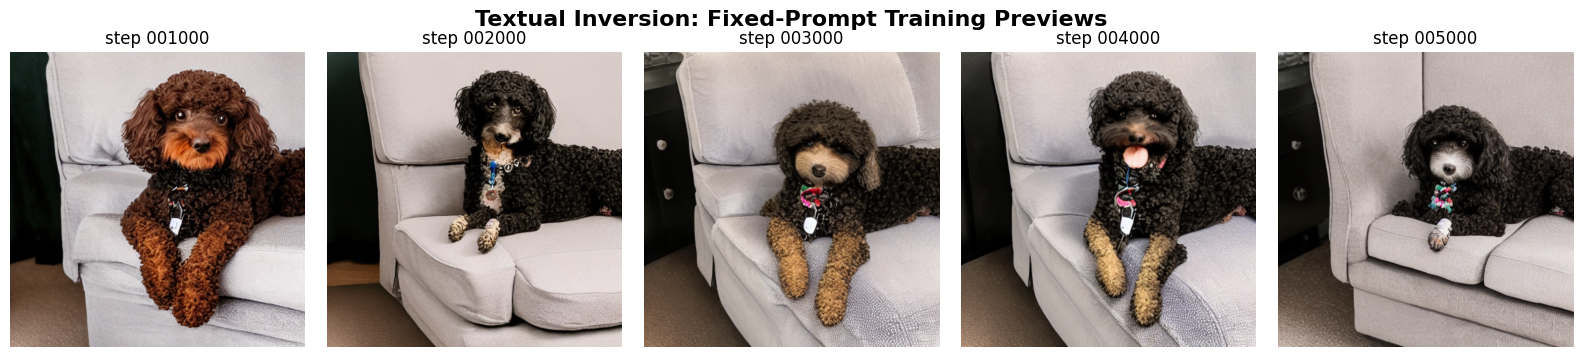

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/textual_inversion_preview_timeline.png


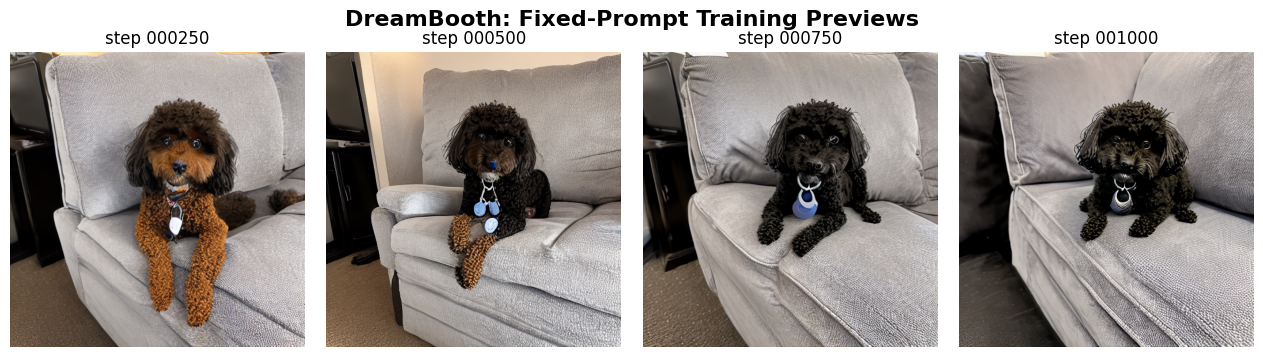

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth_preview_timeline.png


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

PREVIEW_DIRECTORIES = {
    'Textual Inversion': TEXTUAL_INVERSION_OUTPUT_DIRECTORY / 'previews',
    'DreamBooth': DREAMBOOTH_OUTPUT_DIRECTORY / 'previews',
}

for method_display_name, preview_directory in PREVIEW_DIRECTORIES.items():
    preview_image_paths = sorted(preview_directory.glob('preview_step_*.png'))
    if not preview_image_paths:
        print(f'No preview images found for {method_display_name} at {preview_directory}')
        continue

    figure, axes_grid = plt.subplots(
        1,
        len(preview_image_paths),
        figsize=(3.2 * len(preview_image_paths), 3.6),
        squeeze=False,
    )
    for axis, preview_image_path in zip(axes_grid[0], preview_image_paths):
        axis.imshow(Image.open(preview_image_path).convert('RGB'))
        axis.set_title(preview_image_path.stem.replace('preview_', '').replace('_', ' '))
        axis.axis('off')

    figure.suptitle(
        f'{method_display_name}: Fixed-Prompt Training Previews',
        fontsize=16,
        weight='bold',
    )
    figure.tight_layout()
    preview_timeline_path = (
        DRIVE_CHECKPOINTS_ROOT
        / f"{method_display_name.lower().replace(' ', '_')}_preview_timeline.png"
    )
    figure.savefig(
        preview_timeline_path,
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()
    print('Saved preview timeline to:', preview_timeline_path)